# SOAL 1 Dataset MPG (Seaborn)

**Deskripsi:** Dataset berisi spesifikasi mobil dan efisiensi bahan bakar.

**Tugas**
1. Mengurutkan mobil berdasarkan `displ` (menaik & menurun)
2. Memilih kolom tertentu (`manufacturer`, `model`, `cty`, `hwy`)
3. Memfilter mobil dengan `displ` 2.0–4.0 liter dan `cty` ≥ 20
4. Mengelompokkan berdasarkan `class` dan menghitung rata-rata
5. Menambahkan kolom `mpg_avg` dan klasifikasi efisiensi (High/Medium/Low)

## 1. Import Library & Load Dataset

Import `pandas`, `seaborn`, `numpy`, dan load dataset `mpg`.

In [43]:
# Import library
import pandas as pd
from IPython.display import display
import seaborn as sns
import numpy as np

# Load dataset mpg dari seaborn
mpg = sns.load_dataset('mpg')

print("Shape dataset:", mpg.shape)
print("Kolom:", list(mpg.columns))
mpg.head()

Shape dataset: (398, 9)
Kolom: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'name']


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 2. Urutkan Berdasarkan `displ`

Urutkan data berdasarkan `displ` menaik (ascending), lalu menurun (descending).

In [ ]:
# Urutkan displacement menaik
mpg_asc = mpg.sort_values('displacement', ascending=True)
print("=== Displacement Menaik (5 teratas) ===")
display(mpg_asc[['name', 'displacement', 'mpg']].head())

# Urutkan displacement menurun
mpg_desc = mpg.sort_values('displacement', ascending=False)
print("\n=== Displacement Menurun (5 teratas) ===")
display(mpg_desc[['name', 'displacement', 'mpg']].head())

=== Displacement Menaik (5 teratas) ===


,name,displacement,mpg
117,fiat 128,68.0,29.0
334,mazda rx-7 gs,70.0,23.7
71,mazda rx2 coupe,70.0,19.0
111,maxda rx3,70.0,18.0
131,toyota corolla 1200,71.0,32.0



=== Displacement Menurun (5 teratas) ===


,name,displacement,mpg
8,pontiac catalina,455.0,14.0
13,buick estate wagon (sw),455.0,14.0
95,buick electra 225 custom,455.0,12.0
6,chevrolet impala,454.0,14.0
7,plymouth fury iii,440.0,14.0


## 3. Pilih Kolom & Pisahkan `manufacturer` / `model`

Di seaborn, kolom `manufacturer` dan `model` tidak terpisah. Kita pecah dari kolom `name`.

In [ ]:
mpg = sns.load_dataset('mpg')

# Memisahkan kolom name menjadi manufacturer dan model
mpg[['manufacturer', 'model']] = mpg['name'].str.split(
    n=1, expand=True
)

# Memilih kolom yang diperlukan
mpg_selected = mpg[['manufacturer', 'model', 'mpg']].copy()

# Menampilkan hasil
print("=== Kolom Terpilih ===")
display(mpg_selected.head())

=== Kolom Terpilih ===


,manufacturer,model,mpg
0,chevrolet,chevelle malibu,18.0
1,buick,skylark 320,15.0
2,plymouth,satellite,18.0
3,amc,rebel sst,16.0
4,ford,torino,17.0


## 4. Filter Data

Filter mobil dengan `displ` antara 2.0–4.0 liter DAN `cty` ≥ 20.

In [ ]:
# Filter displacement dan mpg
# Catatan: displacement di dataset ini dalam cubic inches (bukan liter), range 120-240 setara dengan mesin menengah
mpg_filtered = mpg[(mpg['displacement'] >= 120) &
                   (mpg['displacement'] <= 240) &
                   (mpg['mpg'] >= 20)].copy()

print(f"Jumlah data setelah filter: {len(mpg_filtered)}")
display(mpg_filtered[['manufacturer','model','displacement','mpg','origin']].head())

Jumlah data setelah filter: 104


,manufacturer,model,displacement,mpg,origin
15,plymouth,duster,198.0,22.0,usa
17,ford,maverick,200.0,21.0,usa
23,bmw,2002,121.0,26.0,europe
24,amc,gremlin,199.0,21.0,usa
30,chevrolet,vega 2300,140.0,28.0,usa


## 5. Group by `class`

Hitung rata-rata `cty`, `hwy`, dan jumlah mobil per kelas.

In [ ]:
# Group by origin (sebagai pengganti class)
mpg_grouped = (mpg_filtered
               .groupby('origin')
               .agg(avg_mpg=('mpg', 'mean'),
                    jumlah_mobil=('mpg', 'count'))
               .reset_index()
               .sort_values('avg_mpg', ascending=False))

print("=== Rata-rata per Origin ===")
display(mpg_grouped)

=== Rata-rata per Origin ===


,origin,avg_mpg,jumlah_mobil
1,japan,26.973333,15
0,europe,25.511111,18
2,usa,24.170423,71


## 6. Tambah Kolom `mpg_avg` & Klasifikasi Efisiensi

- `mpg_avg` = rata-rata `cty` dan `hwy`
- `efisiensi`: **High** (≥30), **Medium** (25–29.99), **Low** (<25)

In [ ]:
# Tambah mpg_avg & kategori efisiensi
def klasifikasi(mpg_avg):
    if mpg_avg >= 30:
        return 'High'
    elif mpg_avg >= 25:
        return 'Medium'
    else:
        return 'Low'

mpg_final = mpg_filtered.copy()
mpg_final['mpg_avg'] = mpg_final['mpg']
mpg_final['efisiensi'] = mpg_final['mpg_avg'].apply(klasifikasi)

print("=== Data Final ===")
display(mpg_final[['manufacturer','model','mpg','mpg_avg','efisiensi']].head(10))

print("\n=== Distribusi Kategori Efisiensi ===")
print(mpg_final['efisiensi'].value_counts())

=== Data Final ===


,manufacturer,model,mpg,mpg_avg,efisiensi
15,plymouth,duster,22.0,22.0,Low
17,ford,maverick,21.0,21.0,Low
23,bmw,2002,26.0,26.0,Medium
24,amc,gremlin,21.0,21.0,Low
30,chevrolet,vega 2300,28.0,28.0,Medium
46,chevrolet,vega (sw),22.0,22.0,Low
49,mercury,capri 2000,23.0,23.0,Low
60,chevrolet,vega,20.0,20.0,Low
61,ford,pinto runabout,21.0,21.0,Low
77,volkswagen,411 (sw),22.0,22.0,Low



=== Distribusi Kategori Efisiensi ===
efisiensi
Low       58
Medium    33
High      13
Name: count, dtype: int64


## 7. Visualisasi

Menampilkan distribusi efisiensi per class dengan `countplot`.

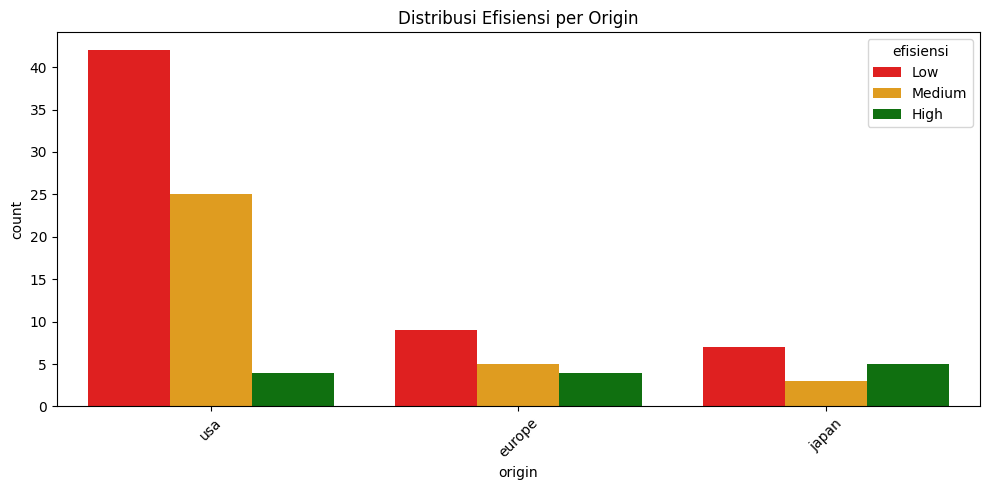

In [ ]:
# Visualisasi berdasarkan origin
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.countplot(data=mpg_final, x='origin', hue='efisiensi',
              palette={'High':'green','Medium':'orange','Low':'red'})
plt.title('Distribusi Efisiensi per Origin')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# SOAL 2 Dataset Diamonds

**Tugas :**
1. Pilih kolom: cut, color, clarity, carat, price.
2. Filter berlian dengan cut = "Ideal" atau "Premium" dan price > 5000.
3. Urutkan data berdasarkan carat menurun.
4. Kelompokkan berdasarkan cut, hitung rata-rata price dan jumlah berlian.
5. Buat kolom baru price_per_carat = price / carat.


### 1. Load Dataset & Pilih Kolom Tertentu

Pilih kolom yang diperlukan: `cut`, `color`, `clarity`, `carat`, dan `price`.

In [74]:
diamonds = sns.load_dataset('diamonds')

# Memilih kolom cut, color, clarity, carat, price
diamonds_selected = diamonds[['cut', 'color', 'clarity', 'carat', 'price']].copy()

display(diamonds.head(10))
display(diamonds_selected.head())

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


,cut,color,clarity,carat,price
0,Ideal,E,SI2,0.23,326
1,Premium,E,SI1,0.21,326
2,Good,E,VS1,0.23,327
3,Premium,I,VS2,0.29,334
4,Good,J,SI2,0.31,335



## 2. Filter Data Berlian

Filter data dengan kriteria:
- `cut` bernilai **'Ideal'** atau **'Premium'**
- `price` lebih besar dari **5000** (`price > 5000`)


In [75]:
# Memfilter data berdasarkan kriteria cut dan price
diamonds_filtered = diamonds_selected[
    (diamonds_selected['cut'].isin(['Ideal', 'Premium'])) &
    (diamonds_selected['price'] > 5000)
].copy()

print(f"Jumlah data setelah filter: {len(diamonds_filtered)}")
display(diamonds_filtered.head())

Jumlah data setelah filter: 9702


,cut,color,clarity,carat,price
11416,Ideal,E,SI2,1.16,5001
11417,Ideal,E,SI2,1.16,5001
11420,Premium,D,VS2,0.90,5001
11421,Ideal,I,SI1,1.07,5002
11422,Ideal,H,SI2,1.10,5002



## 3. Urutkan Data Berdasarkan Carat

Urutkan data hasil filter berdasarkan kolom `carat` secara menurun (descending).


In [76]:
# Mengurutkan berdasarkan carat secara menurun
diamonds_sorted = diamonds_filtered.sort_values(by='carat', ascending=False)

print("=== Data Terurut Berdasarkan Carat Menurun (5 teratas) ===")
display(diamonds_sorted.head())

=== Data Terurut Berdasarkan Carat Menurun (5 teratas) ===


,cut,color,clarity,carat,price
25999,Premium,J,I1,4.01,15223
25998,Premium,I,I1,4.01,15223
26534,Premium,I,I1,3.67,16193
27679,Premium,J,VS2,3.51,18701
24328,Ideal,H,I1,3.50,12587



## 4. Pengelompokan (Group by) Berdasarkan Cut

Kelompokkan data berdasarkan kolom `cut`, lalu hitung rata-rata `price` dan jumlah berlian pada masing-masing grup

In [77]:
# Mengelompokkan berdasarkan cut dan agregasi rata-rata price serta hitung jumlah berlian
diamonds_grouped = (diamonds_sorted
                    .groupby('cut', observed=False)
                    .agg(avg_price=('price', 'mean'),
                         jumlah_berlian=('price', 'count'))
                    .reset_index())

print("=== Ringkasan Berdasarkan Cut ===")
display(diamonds_grouped)

=== Ringkasan Berdasarkan Cut ===


,cut,avg_price,jumlah_berlian
0,Ideal,9335.894082,4985
1,Premium,9507.518974,4717
2,Very Good,NaN,0
3,Good,NaN,0
4,Fair,NaN,0



## 5. Tambah Kolom `price_per_carat`

Buat kolom baru `price_per_carat` dengan rumus:

$$\text{price_per_carat} = \frac{\text{price}}{\text{carat}}$$


In [78]:
# Menambahkan kolom price_per_carat pada data terurut
diamonds_final = diamonds_sorted.copy()
diamonds_final['price_per_carat'] = diamonds_final['price'] / diamonds_final['carat']

print("=== Data Final dengan Kolom price_per_carat (10 teratas) ===")
display(diamonds_final[['cut', 'color', 'clarity', 'carat', 'price', 'price_per_carat']].head(10))

=== Data Final dengan Kolom price_per_carat (10 teratas) ===


,cut,color,clarity,carat,price,price_per_carat
25999,Premium,J,I1,4.01,15223,3796.259352
25998,Premium,I,I1,4.01,15223,3796.259352
26534,Premium,I,I1,3.67,16193,4412.261580
27679,Premium,J,VS2,3.51,18701,5327.920228
24328,Ideal,H,I1,3.50,12587,3596.285714
24131,Premium,H,I1,3.24,12300,3796.296296
24297,Ideal,I,I1,3.22,12545,3895.962733
22428,Premium,E,I1,3.05,10453,3427.213115
27638,Premium,I,SI2,3.04,18559,6104.934211
27514,Premium,I,SI2,3.01,18242,6060.465116


# SOAL 3 Dataset mssleep
**Tugas :**
1. Pilih kolom: name, order, sleep_total, bodywt.
2. Filter mamalia dengan sleep_total ≥ 10 jam.
3. Urutkan berdasarkan bodywt menurun.
4. Kelompokkan berdasarkan order, hitung jumlah spesies, rata-rata tidur, berat maksimum.
5. Tambahkan kolom baru sleep_efficiency = "High" jika tidur > 12 jam, "Low" jika ≤ 12 jam.



## 1. Load Dataset & Pilih Kolom Tertentu

Pilih kolom yang diperlukan: `name`, `order`, `sleep_total`, dan `bodywt`.


In [45]:
url = "https://raw.githubusercontent.com/tidyverse/ggplot2/main/data-raw/msleep.csv"

msleep = pd.read_csv(url)

print("=== Dataset Asli msleep ===")
display(msleep)

print("Ukuran dataset:", msleep.shape)

=== Dataset Asli msleep ===


,name,genus,vore,order,conservation,sleep_total,sleep_rem,sleep_cycle,awake,brainwt,bodywt
0,Cheetah,Acinonyx,carni,Carnivora,lc,12.1,NaN,NaN,11.9,NaN,50.000
1,Owl monkey,Aotus,omni,Primates,NaN,17.0,1.8,NaN,7.0,0.01550,0.480
2,Mountain beaver,Aplodontia,herbi,Rodentia,nt,14.4,2.4,NaN,9.6,NaN,1.350
3,Greater short-tailed shrew,Blarina,omni,Soricomorpha,lc,14.9,2.3,0.133333,9.1,0.00029,0.019
4,Cow,Bos,herbi,Artiodactyla,domesticated,4.0,0.7,0.666667,20.0,0.42300,600.000
...,...,...,...,...,...,...,...,...,...,...,...
78,Tree shrew,Tupaia,omni,Scandentia,NaN,8.9,2.6,0.233333,15.1,0.00250,0.104
79,Bottle-nosed dolphin,Tursiops,carni,Cetacea,NaN,5.2,NaN,NaN,18.8,NaN,173.330
80,Genet,Genetta,carni,Carnivora,NaN,6.3,1.3,NaN,17.7,0.01750,2.000
81,Arctic fox,Vulpes,carni,Carnivora,NaN,12.5,NaN,NaN,11.5,0.04450,3.380


Ukuran dataset: (83, 11)


In [47]:
# 1. Pilih kolom: name, order, sleep_total, bodywt
msleep_selected = msleep[['name', 'order', 'sleep_total', 'bodywt']]
print("Setelah memilih kolom:")
print(msleep_selected.head())
print(f"Jumlah kolom: {len(msleep_selected.columns)}\n")

Setelah memilih kolom:
                         name         order  sleep_total   bodywt
0                     Cheetah     Carnivora         12.1   50.000
1                  Owl monkey      Primates         17.0    0.480
2             Mountain beaver      Rodentia         14.4    1.350
3  Greater short-tailed shrew  Soricomorpha         14.9    0.019
4                         Cow  Artiodactyla          4.0  600.000
Jumlah kolom: 4




## 2. Filter Mamalia dengan Waktu Tidur Panjang

Saring data untuk mamalia yang memiliki total waktu tidur (`sleep_total`) minimal 10 jam.


In [50]:
# 2. Filter mamalia dengan sleep_total >= 10 jam
msleep_filtered = msleep_selected[msleep_selected['sleep_total'] >= 10]
print("Setelah filtering (sleep_total >= 10 jam):")
print(msleep_filtered.head())
print(f"Jumlah baris setelah filter: {len(msleep_filtered)}\n")

Setelah filtering (sleep_total >= 10 jam):
                         name         order  sleep_total  bodywt
0                     Cheetah     Carnivora         12.1  50.000
1                  Owl monkey      Primates         17.0   0.480
2             Mountain beaver      Rodentia         14.4   1.350
3  Greater short-tailed shrew  Soricomorpha         14.9   0.019
5            Three-toed sloth        Pilosa         14.4   3.850
Jumlah baris setelah filter: 45




## 3. Urutkan Data Berdasarkan Berat Badan

Urutkan data mamalia hasil filter berdasarkan berat tubuh (`bodywt`) secara menurun.

In [51]:
# 3. Urutkan berdasarkan bodywt menurun
msleep_sorted = msleep_filtered.sort_values(by='bodywt', ascending=False)
print("Setelah diurutkan berdasarkan bodywt (menurun):")
print(msleep_sorted.head())
print(f"Bodywt terbesar: {msleep_sorted['bodywt'].iloc[0]}\n")

Setelah diurutkan berdasarkan bodywt (menurun):
               name      order  sleep_total   bodywt
50            Tiger  Carnivora         15.8  162.564
52             Lion  Carnivora         13.5  161.499
51           Jaguar  Carnivora         10.4  100.000
61  Giant armadillo  Cingulata         18.1   60.000
0           Cheetah  Carnivora         12.1   50.000
Bodywt terbesar: 162.564




## 4. Analisis Grup Berdasarkan Ordo (Order)

Kelompokkan data berdasarkan kolom `order` untuk menghitung jumlah spesies, rata-rata durasi tidur, dan berat badan maksimum.


In [52]:
# 4. Kelompokkan berdasarkan order, hitung jumlah spesies, rata-rata tidur, berat maksimum
msleep_grouped = msleep_sorted.groupby('order').agg(
    species_count=('name', 'count'),
    average_sleep=('sleep_total', 'mean'),
    max_bodywt=('bodywt', 'max')
).reset_index()
print("Setelah pengelompokan berdasarkan order:")
print(msleep_grouped)
print(f"Order yang ditemukan: {msleep_grouped['order'].tolist()}\n")

Setelah pengelompokan berdasarkan order:
              order  species_count  average_sleep  max_bodywt
0      Afrosoricida              1      15.600000       0.900
1         Carnivora              7      12.414286     162.564
2        Chiroptera              2      19.800000       0.023
3         Cingulata              2      17.750000      60.000
4   Didelphimorphia              2      18.700000       1.700
5     Diprotodontia              2      12.400000       1.620
6    Erinaceomorpha              2      10.200000       0.770
7            Pilosa              1      14.400000       3.850
8          Primates              6      11.666667      10.000
9          Rodentia             17      13.717647       1.350
10     Soricomorpha              3      12.666667       0.060
Order yang ditemukan: ['Afrosoricida', 'Carnivora', 'Chiroptera', 'Cingulata', 'Didelphimorphia', 'Diprotodontia', 'Erinaceomorpha', 'Pilosa', 'Primates', 'Rodentia', 'Soricomorpha']




## 5. Tambah kolom Efisiensi Tidur (`sleep_efficiency`)

Tambahkan kolom baru dengan ketentuan kategori:
- **High**: Jika total tidur > 12 jam.
- **Low**: Jika total tidur ≤ 12 jam.


In [53]:
# 5. Tambahkan kolom baru sleep_efficiency
msleep_final = msleep_sorted.copy()
msleep_final['sleep_efficiency'] = msleep_final['sleep_total'].apply(lambda x: 'High' if x > 12 else 'Low')
print("Setelah menambahkan kolom sleep_efficiency:")
print(msleep_final.head())
print(f"Distribusi sleep_efficiency: {msleep_final['sleep_efficiency'].value_counts().to_dict()}")

Setelah menambahkan kolom sleep_efficiency:
               name      order  sleep_total   bodywt sleep_efficiency
50            Tiger  Carnivora         15.8  162.564             High
52             Lion  Carnivora         13.5  161.499             High
51           Jaguar  Carnivora         10.4  100.000              Low
61  Giant armadillo  Cingulata         18.1   60.000             High
0           Cheetah  Carnivora         12.1   50.000             High
Distribusi sleep_efficiency: {'High': 31, 'Low': 14}


# SOAL 4 Dataset Flights

Tugas:
1. Pilih kolom: year, month, day, dep_delay, arr_delay, distance, dan air_time.
2. Filter data: Pilih penerbangan dengan dep_delay >= 60 atau arr_delay >= 60.
3. Urutkan data: Urutkan berdasarkan distance secara menurun.
4. Kelompokkan data: Kelompokkan berdasarkan month, kemudian hitung rata-rata dep_delay dan arr_delay.
5. Tambahkan kolom baru: time_gain dan speed.

## 1. Load Dataset Flights

Memuat data penerbangan dari file CSV eksternal.

In [68]:
# Memuat dataset flights dari file csv eksternal.
flights = pd.read_csv('/content/flights.csv')
display(flights.head())

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00


## 2. Pilih Kolom Tertentu

Memilih beberapa kolom relevan yang akan digunakan untuk analisis penerbangan.

In [69]:
# Memilih kolom spesifik dari dataset flights untuk analisis.
flights_selected = flights[['year', 'month', 'day', 'dep_delay', 'arr_delay', 'distance', 'air_time']].copy()
display(flights_selected.head())

,year,month,day,dep_delay,arr_delay,distance,air_time
0,2013,1,1,2.0,11.0,1400,227.0
1,2013,1,1,4.0,20.0,1416,227.0
2,2013,1,1,2.0,33.0,1089,160.0
3,2013,1,1,-1.0,-18.0,1576,183.0
4,2013,1,1,-6.0,-25.0,762,116.0


## 3. Filter Data Delay

Menyaring data untuk mengambil penerbangan yang mengalami keterlambatan keberangkatan atau kedatangan minimal 60 menit.

In [70]:
# Menyaring data penerbangan yang mengalami delay minimal 60 menit.
flights_filtered = flights_selected[(flights_selected['dep_delay'] >= 60) | (flights_selected['arr_delay'] >= 60)].copy()
display(flights_filtered.head())

,year,month,day,dep_delay,arr_delay,distance,air_time
119,2013,1,1,101.0,137.0,544,118.0
135,2013,1,1,71.0,51.0,1089,160.0
151,2013,1,1,853.0,851.0,184,41.0
218,2013,1,1,144.0,123.0,200,37.0
268,2013,1,1,134.0,145.0,1416,248.0


## 4. Urutkan Data Berdasarkan Distance menurun

Mengurutkan data penerbangan hasil filter berdasarkan kolom jarak secara menurun.

In [71]:
# Mengurutkan data penerbangan berdasarkan distance menurun.
flights_sorted = flights_filtered.sort_values(by='distance', ascending=False).copy()
display(flights_sorted.head())

,year,month,day,dep_delay,arr_delay,distance,air_time
19409,2013,1,23,101.0,82.0,4983,653.0
131143,2013,2,23,206.0,126.0,4983,599.0
7072,2013,1,9,1301.0,1272.0,4983,640.0
4551,2013,1,6,79.0,28.0,4983,611.0
133681,2013,2,26,60.0,-27.0,4983,584.0


## 5. Kelompokkan Data per Bulan

Mengelompokkan data berdasarkan bulan dan menghitung rata-rata keterlambatan keberangkatan serta kedatangan.

In [72]:
# Menghitung rata-rata delay keberangkatan dan kedatangan per bulan.
flights_grouped = flights_sorted.groupby('month').agg(
    average_dep_delay=('dep_delay', 'mean'),
    average_arr_delay=('arr_delay', 'mean')
).reset_index()
display(flights_grouped)

,month,average_dep_delay,average_arr_delay
0,1,104.176716,108.052730
1,2,106.331414,105.903379
2,3,108.935004,109.509503
3,4,105.949351,114.372643
4,5,106.585688,107.874815
5,6,111.061258,119.642657
6,7,109.442047,118.119837
7,8,102.249027,107.002488
8,9,117.304348,118.890039
9,10,103.863781,100.445791


## 6. Tambah Kolom Baru

Menambahkan dua kolom baru pada data penerbangan, yaitu time_gain dan speed

Rumus:

time_gain = dep_delay − arr_delay

speed = (distance / air_time) × 60

In [73]:
# Membuat kolom baru berupa keuntungan selisih waktu dan kecepatan terbang.
flights_final = flights_sorted.copy()
flights_final['time_gain'] = flights_final['dep_delay'] - flights_final['arr_delay']
flights_final['speed'] = (flights_final['distance'] / flights_final['air_time']) * 60
display(flights_final.head())

,year,month,day,dep_delay,arr_delay,distance,air_time,time_gain,speed
19409,2013,1,23,101.0,82.0,4983,653.0,19.0,457.856049
131143,2013,2,23,206.0,126.0,4983,599.0,80.0,499.131886
7072,2013,1,9,1301.0,1272.0,4983,640.0,29.0,467.156250
4551,2013,1,6,79.0,28.0,4983,611.0,51.0,489.328969
133681,2013,2,26,60.0,-27.0,4983,584.0,87.0,511.952055
